In [1]:
%matplotlib inline

In [2]:
import numpy as np
import pandas as pd

In [3]:
pv = pd.read_csv("../data/vehicles.csv")
pr = pd.read_csv("../data/reservations.csv")

In [4]:
pv.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   vehicle_id         1000 non-null   int64  
 1   technology         1000 non-null   int64  
 2   actual_price       1000 non-null   float64
 3   recommended_price  1000 non-null   int64  
 4   num_images         1000 non-null   int64  
 5   street_parked      1000 non-null   int64  
 6   description        1000 non-null   int64  
dtypes: float64(1), int64(6)
memory usage: 54.8 KB


In [5]:
pr.info()

<class 'pandas.DataFrame'>
RangeIndex: 6376 entries, 0 to 6375
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   vehicle_id  6376 non-null   int64
 1   created_at  6376 non-null   str  
dtypes: int64(1), str(1)
memory usage: 99.8 KB


In [6]:
pr["vehicle_id"].value_counts().to_frame()

,count
vehicle_id,
247,25
483,25
687,25
690,24
812,24
...,...
639,1
36,1
222,1


<Axes: >

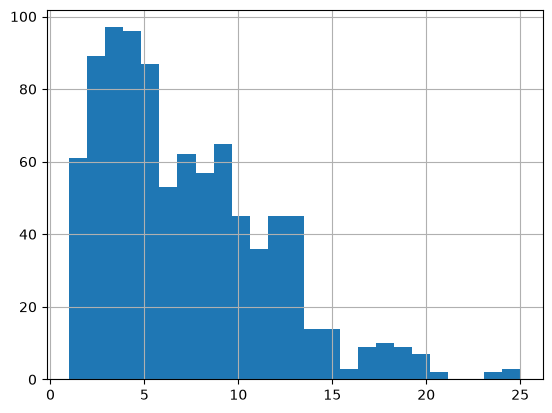

In [7]:
pr["vehicle_id"].value_counts().hist(bins=25)

In [8]:
pdf = pv.merge(
    pr["vehicle_id"].value_counts().to_frame(), on="vehicle_id", how="left"
).rename(columns={"count": "n_reservations"})

pdf["n_reservations"] = pdf["n_reservations"].fillna(0)

In [9]:
pdf["price_ratio"] = pdf["actual_price"] / pdf["recommended_price"]
pdf["price_diff"] = pdf["actual_price"] - pdf["recommended_price"]

array([[<Axes: title={'center': 'vehicle_id'}>,
        <Axes: title={'center': 'technology'}>,
        <Axes: title={'center': 'actual_price'}>],
       [<Axes: title={'center': 'recommended_price'}>,
        <Axes: title={'center': 'num_images'}>,
        <Axes: title={'center': 'street_parked'}>],
       [<Axes: title={'center': 'description'}>,
        <Axes: title={'center': 'n_reservations'}>,
        <Axes: title={'center': 'price_ratio'}>],
       [<Axes: title={'center': 'price_diff'}>, <Axes: >, <Axes: >]],
      dtype=object)

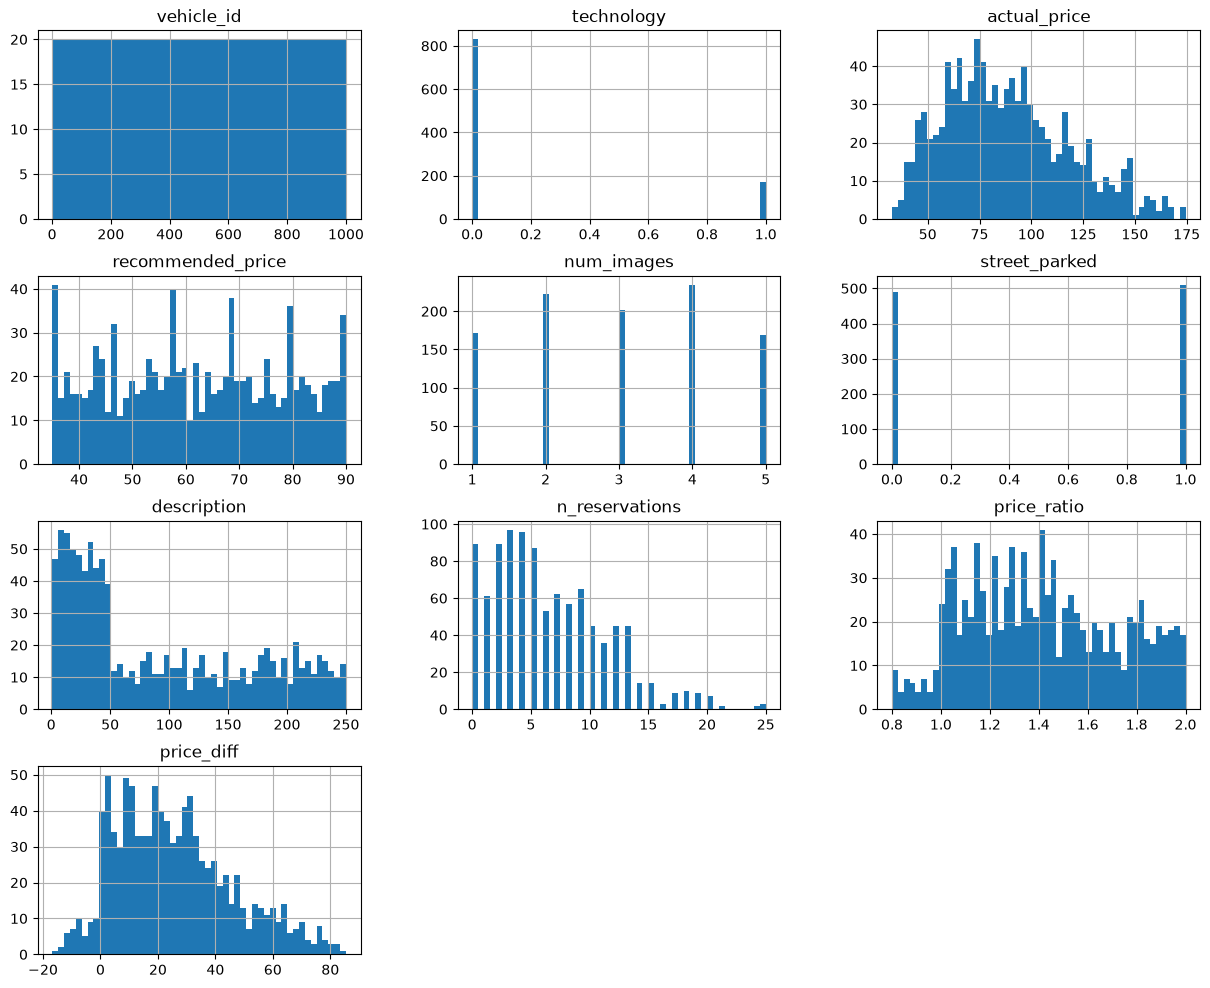

In [10]:
pdf.hist(bins=50, figsize=(15, 12))

In [11]:
(
    pdf.groupby(["technology", "price_ratio", "description", "num_images"])
    .size()
    .reset_index(name="count")
    .sort_values("count", ascending=False)
)

,technology,price_ratio,description,num_images,count
533,0,1.56,98,5,2
143,0,1.14,36,4,2
240,0,1.25,21,1,2
665,0,1.78,38,2,1
669,0,1.78,237,3,1
...,...,...,...,...,...
338,0,1.35,150,1,1
339,0,1.35,175,3,1
340,0,1.35,200,4,1
341,0,1.36,1,3,1


In [12]:
# Test Split: the pipeline's own split, so a vehicle lands on the same side here
# and in a training run.
import sys

sys.path.append("..")

from ml.tasks.split_train_test import TEST_SIZE, hash_fraction

is_test = pdf["vehicle_id"].map(lambda v: hash_fraction(v, "v1")) < TEST_SIZE
test, training = pdf[is_test], pdf[~is_test]

print(len(test), len(training), len(test) / len(pdf))

191 809 0.191


In [13]:
pdf["n_reservations"].value_counts()

n_reservations
3.0     97
4.0     96
2.0     89
0.0     89
5.0     87
9.0     65
7.0     62
1.0     61
8.0     57
6.0     53
13.0    45
12.0    45
10.0    45
11.0    36
14.0    14
15.0    14
18.0    10
17.0     9
19.0     9
20.0     7
16.0     3
25.0     3
21.0     2
24.0     2
Name: count, dtype: int64

In [14]:
import pandas as pd

pdf["reservation_bin"] = pd.cut(
    pdf["n_reservations"],
    bins=[-0.1, 2, 5, 9, 13, np.inf],
    labels=["0-2", "3-5", "6-9", "10-13", "14+"],
)
print(pdf["reservation_bin"].value_counts().sort_index())

reservation_bin
0-2      239
3-5      280
6-9      237
10-13    171
14+       73
Name: count, dtype: int64


In [15]:
from ml.tasks.split_train_test import target_distribution_by_bin

train_set, test_set = pdf[~is_test].copy(), pdf[is_test].copy()

# the table the pipeline records next to every run: train and test cover the same demand
print(target_distribution_by_bin(pdf, is_test))

train_set.drop(columns="reservation_bin", inplace=True)
test_set.drop(columns="reservation_bin", inplace=True)

                rows  full_share  train_share  test_share
n_reservations                                           
0-2              239       0.239        0.242       0.225
3-5              280       0.280        0.274       0.304
6-9              237       0.237        0.244       0.209
10-13            171       0.171        0.173       0.162
14+               73       0.073        0.067       0.099


In [16]:
df = train_set.copy()

In [17]:
df["n_reservations"].describe()

count    809.000000
mean       6.302843
std        4.833721
min        0.000000
25%        3.000000
50%        5.000000
75%        9.000000
max       25.000000
Name: n_reservations, dtype: float64

In [18]:
df["n_reservations"].skew()

np.float64(0.8986185903762594)

<Axes: >

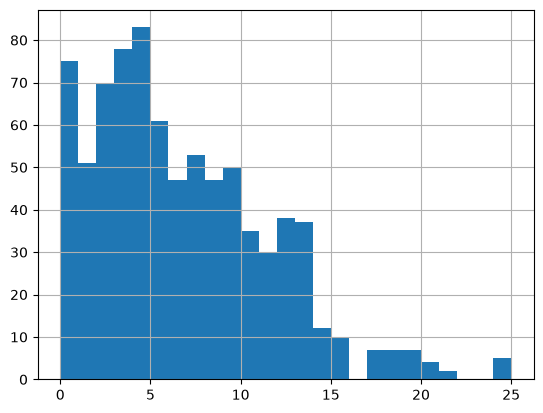

In [19]:
df["n_reservations"].hist(bins=25)

In [20]:
matrix_corr = df.corr()

In [21]:
matrix_corr["n_reservations"].sort_values(key=lambda x: abs(x), ascending=False)

n_reservations       1.000000
price_ratio         -0.379833
price_diff          -0.349772
actual_price        -0.243192
num_images           0.230848
technology           0.140077
street_parked       -0.039807
description          0.025775
vehicle_id           0.024404
recommended_price   -0.007704
Name: n_reservations, dtype: float64

In [22]:
df["noise"] = np.random.random(len(df))

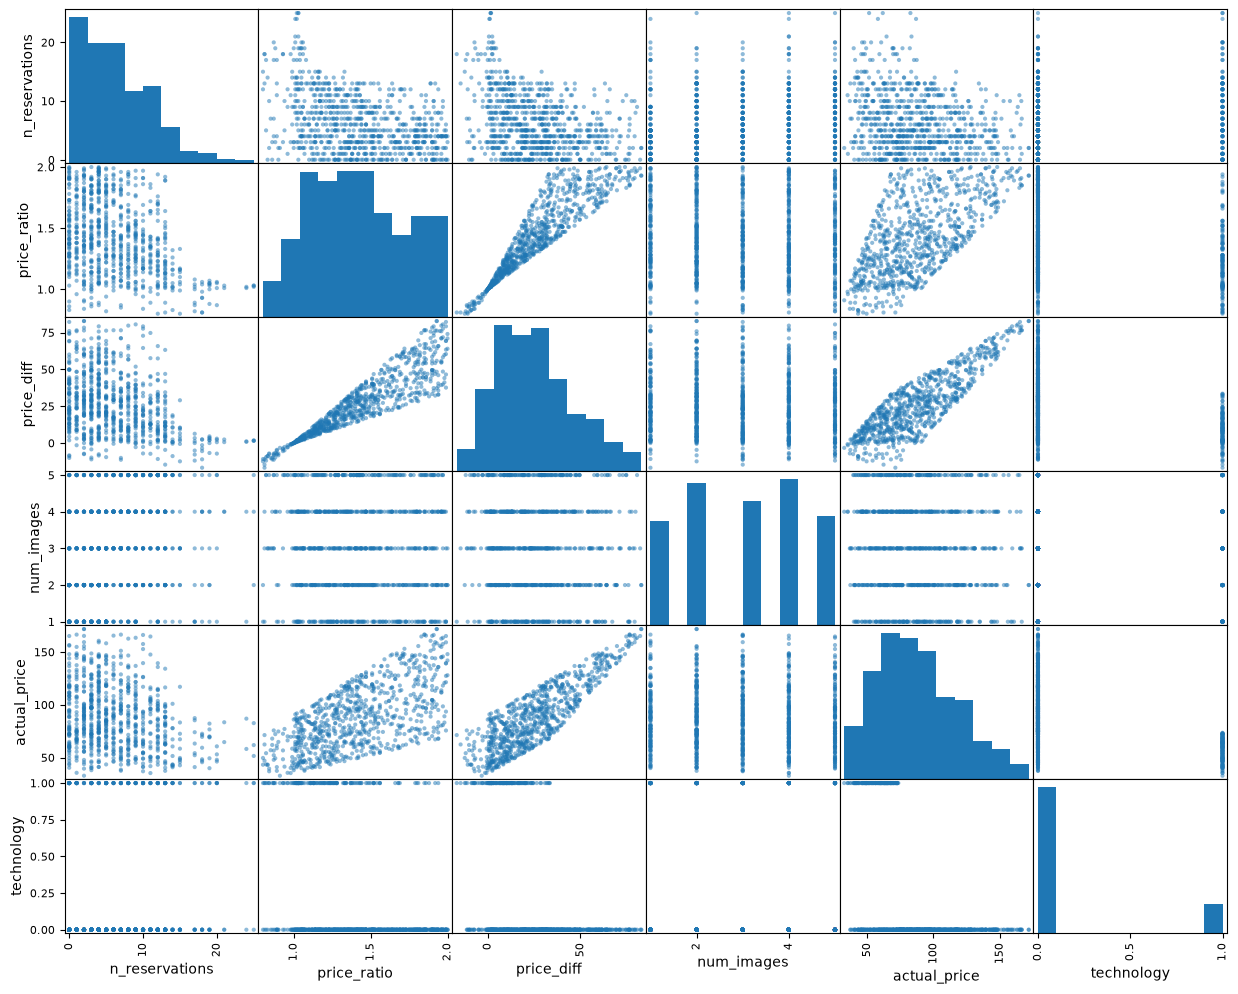

In [23]:
pd.plotting.scatter_matrix(
    df[
        [
            "n_reservations",
            "price_ratio",
            "price_diff",
            "num_images",
            "actual_price",
            "technology",
            # "noise",
        ]
    ],
    figsize=(15, 12),
);

In [24]:
# price_ratio and diff are given the same information, so I will take only ratio

In [25]:
num = ["n_reservations", "actual_price", "price_ratio", "num_images"]

q1 = df[num].quantile(0.25)
q3 = df[num].quantile(0.75)
iqr = q3 - q1
print("IQR:")
print(((df[num] < (q1 - 1.5 * iqr)) | (df[num] > (q3 + 1.5 * iqr))).sum())

print("\n\n\nz-score:")
z = (df[num] - df[num].mean()) / df[num].std()
print((z.abs() > 3).sum())  # z-score

print("\n\n\npercentiles:")
print(df[num].describe(percentiles=[0.01, 0.05, 0.5, 0.95, 0.99]))  # percentiles

IQR:
n_reservations    18
actual_price       0
price_ratio        0
num_images         0
dtype: int64



z-score:
n_reservations    7
actual_price      0
price_ratio       0
num_images        0
dtype: int64



percentiles:
       n_reservations  actual_price  price_ratio  num_images
count      809.000000    809.000000   809.000000  809.000000
mean         6.302843     88.207837     1.417194    3.021014
std          4.833721     30.123000     0.304128    1.351861
min          0.000000     32.760000     0.800000    1.000000
1%           0.000000     39.513600     0.830800    1.000000
5%           0.000000     45.580000     0.990000    1.000000
50%          5.000000     84.180000     1.390000    3.000000
95%         15.000000    145.064000     1.930000    5.000000
99%         20.000000    164.604800     1.990000    5.000000
max         25.000000    171.770000     2.000000    5.000000


# Explore Models

In [26]:
# I want to predict a discrete non negative value, so I will try Poisson first

In [29]:
TARGET = "n_reservations"  # what we predict
# price_ratio alone: the correlation study showed it carries price_diff's signal
FEATURES = ["price_ratio", "technology", "num_images"]


def generate_training_test_set(vehicles_path: str, reservations_path: str):
    vehicles = pd.read_csv(vehicles_path)
    reservations = pd.read_csv(reservations_path)

    # 1. reservations per vehicle -> n_reservations
    counts = reservations["vehicle_id"].value_counts().to_frame()
    df = vehicles.merge(counts, on="vehicle_id", how="left")
    df = df.rename(columns={"count": "n_reservations"})
    df["n_reservations"] = df["n_reservations"].fillna(0).astype(int)

    # 2. price features
    df["price_ratio"] = df["actual_price"] / df["recommended_price"]
    df["price_diff"] = df["actual_price"] - df["recommended_price"]

    # 3. the pipeline's split, so the modelling numbers are the ones a run reproduces
    is_test = df["vehicle_id"].map(lambda v: hash_fraction(v, "v1")) < TEST_SIZE
    train_set, test_set = df[~is_test], df[is_test]

    # 4. split the target from the features
    X_train = train_set[FEATURES]
    y_train = train_set[TARGET]
    X_test = test_set[FEATURES]
    y_test = test_set[TARGET]

    return X_train, y_train, X_test, y_test

In [30]:
X_train, y_train, X_test, y_test = generate_training_test_set(
    "../data/vehicles.csv", "../data/reservations.csv"
)

In [31]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline

In [32]:
from utils import clip_ratio

preprocessing = ColumnTransformer(
    [
        ("ratio", clip_ratio, ["price_ratio"]),
        ("imgs", SimpleImputer(strategy="constant", fill_value=1), ["num_images"]),
        ("tech", SimpleImputer(strategy="constant", fill_value=0), ["technology"]),
    ]
)

In [33]:
# GAM preprocessing: spline-expand price_ratio, keep the rest as linear terms.
from sklearn.preprocessing import SplineTransformer

gam_preprocessing = ColumnTransformer(
    [
        ("ratio", make_pipeline(clip_ratio, SplineTransformer()), ["price_ratio"]),
        ("imgs", SimpleImputer(strategy="constant", fill_value=1), ["num_images"]),
        ("tech", SimpleImputer(strategy="constant", fill_value=0), ["technology"]),
    ]
)

In [34]:
from sklearn.linear_model import LassoCV
from sklearn.preprocessing import StandardScaler

lasso_pipeline = make_pipeline(
    preprocessing, StandardScaler(), LassoCV(cv=10, random_state=0)
)
lasso_pipeline.fit(X_train, y_train)
names = lasso_pipeline[:-1].get_feature_names_out()
list(zip(names, lasso_pipeline[-1].coef_))

[('ratio__price_ratio', np.float64(-1.7246976733478356)),
 ('imgs__num_images', np.float64(1.0358274431909942)),
 ('tech__technology', np.float64(0.20468677754106857))]

In [35]:
from sklearn.metrics import root_mean_squared_error


def calculate_rmse_model(model):
    reg = make_pipeline(preprocessing, model)
    reg.fit(X_train, y_train)

    return root_mean_squared_error(y_train, reg.predict(X_train))

In [36]:
from sklearn.linear_model import PoissonRegressor

calculate_rmse_model(PoissonRegressor())

4.488442718666283

In [37]:
from sklearn.linear_model import LinearRegression

calculate_rmse_model(LinearRegression())

4.341925733895052

In [38]:
from sklearn.linear_model import Lasso

calculate_rmse_model(Lasso())

4.758176909321579

In [39]:
from sklearn.tree import DecisionTreeRegressor

calculate_rmse_model(DecisionTreeRegressor())

2.4589166550749257

In [40]:
from sklearn.model_selection import RepeatedKFold, cross_val_score

CV = RepeatedKFold(n_splits=5, n_repeats=5, random_state=7)


def cv_rmse(model, X, y, cv=CV):
    """Cross-validated RMSE (mean, std) for a model or pipeline.

    Scores on held-out folds, so it measures generalisation rather than
    how well the model memorised the training set.
    """
    scores = -cross_val_score(model, X, y, cv=cv, scoring="neg_root_mean_squared_error")
    return scores.mean(), scores.std()


def compare_models(models, X, y, cv=CV):
    """CV RMSE for a {name: model} mapping, sorted best-first."""
    rows = [(name, *cv_rmse(m, X, y, cv)) for name, m in models.items()]
    return (
        pd.DataFrame(rows, columns=["model", "cv_rmse", "std"])
        .sort_values("cv_rmse")
        .reset_index(drop=True)
    )

In [41]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LassoCV, LinearRegression, PoissonRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor

models = {
    "Dummy (mean)": DummyRegressor(strategy="mean"),
    "Linear": make_pipeline(preprocessing, LinearRegression()),
    "LassoCV": make_pipeline(
        preprocessing, StandardScaler(), LassoCV(cv=10, random_state=0)
    ),
    "Poisson": make_pipeline(preprocessing, StandardScaler(), PoissonRegressor()),
    "GAM (spline on price_ratio)": make_pipeline(
        gam_preprocessing, StandardScaler(), LinearRegression()
    ),
    "Tree (default)": make_pipeline(
        preprocessing, DecisionTreeRegressor(random_state=0)
    ),
    "Tree (depth=3)": make_pipeline(
        preprocessing, DecisionTreeRegressor(max_depth=3, random_state=0)
    ),
}

compare_models(models, X_train, y_train)

,model,cv_rmse,std
0,GAM (spline on price_ratio),4.331850,0.203306
1,Linear,4.362425,0.206785
2,LassoCV,4.364963,0.203174
3,Tree (depth=3),4.375365,0.207759
4,Poisson,4.386367,0.205582
5,Dummy (mean),4.828904,0.227815
6,Tree (default),5.691045,0.372126


In [42]:
def lookalike_groups(df, target="n_reservations", price_bins=10):
    key = ["technology", "num_images", pd.qcut(df.price_ratio, price_bins)]
    g = df.groupby(key, observed=True)[target]
    out = pd.DataFrame(
        {
            "n": g.size(),
            "min": g.min(),
            "max": g.max(),
            "mean": g.mean().round(1),
            "std": g.std().round(2),
        }
    )
    out["range"] = out["max"] - out["min"]
    return out.sort_values(["range", "n"], ascending=False)


lookalike_groups(df).head(8)

n  min   max  mean   std  range
technology num_images price_ratio                                    
1          4          (0.799, 1.03]   9  0.0  25.0  11.4  9.71   25.0
0          2          (0.799, 1.03]   6  0.0  25.0  10.3  9.03   25.0
1          5          (0.799, 1.03]  11  2.0  25.0  13.2  7.32   23.0
0          1          (0.799, 1.03]   9  2.0  24.0  10.3  7.76   22.0
           4          (0.799, 1.03]  13  0.0  21.0  11.9  7.01   21.0
                      (1.03, 1.13]   12  0.0  19.0   7.7  6.56   19.0
1          3          (1.03, 1.13]    6  1.0  20.0   8.8  6.74   19.0
0          3          (0.799, 1.03]  10  0.0  18.0   9.9  5.13   18.0

## Question 1 - findings

Model parameters and the price_ratio response, using the split and features defined above.


In [43]:
from sklearn.linear_model import LinearRegression

# Linear model parameters, raw scale (same split and features as the models above).
linear = LinearRegression().fit(X_train[FEATURES], y_train)
terms = " ".join(f"{c:+.2f}*{f}" for f, c in zip(FEATURES, linear.coef_))
print("Linear model, raw scale:")
print(f"  n_reservations = {linear.intercept_:.2f} {terms}")

# Standardized coefficient = reservations per +1 std of the feature (comparable across features).
importance = pd.DataFrame(
    {"coef": linear.coef_, "std": X_train[FEATURES].std()}, index=FEATURES
).assign(coef_per_1std=lambda t: t["coef"] * t["std"])
importance = importance.sort_values("coef_per_1std", key=abs, ascending=False)
print("\nStandardized coefficients (reservations per +1 std):")
print(importance.round(2).to_string())

Linear model, raw scale:
  n_reservations = 11.94 -5.69*price_ratio +0.57*technology +0.77*num_images

Standardized coefficients (reservations per +1 std):
             coef   std  coef_per_1std
price_ratio -5.69  0.30          -1.73
num_images   0.77  1.35           1.04
technology   0.57  0.37           0.21


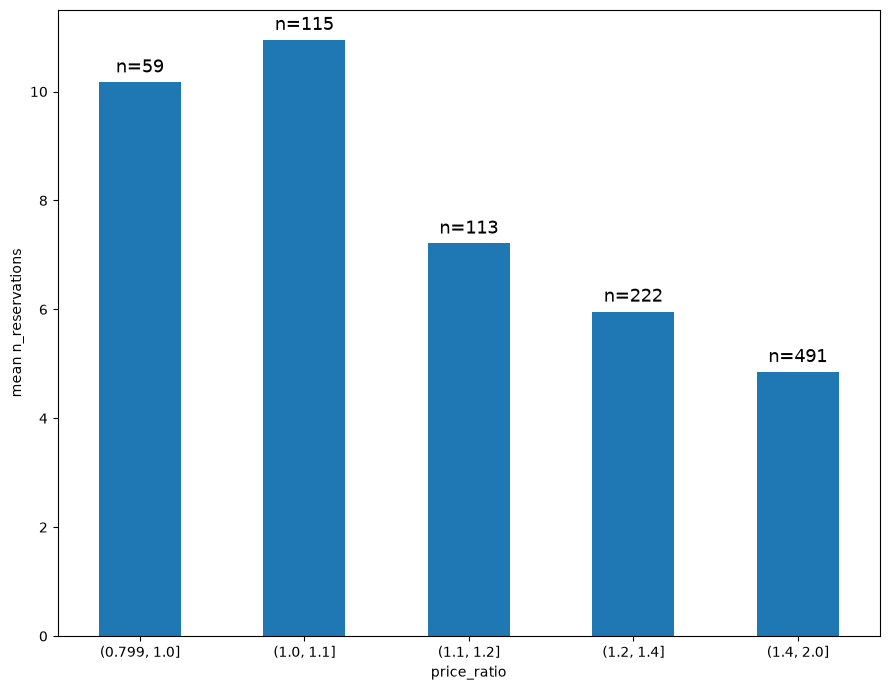

In [44]:
import matplotlib.pyplot as plt

agg = (
    pdf.groupby(
        pd.cut(pdf.price_ratio, [0.8, 1.0, 1.1, 1.2, 1.4, 2.0], include_lowest=True)
    )["n_reservations"]
    .agg(n="size", mean="mean")
    .round(2)
)

fig, ax = plt.subplots(figsize=(9, 7))
agg["mean"].plot.bar(ax=ax, rot=0, ylabel="mean n_reservations", xlabel="price_ratio")

ax.bar_label(
    ax.containers[0], labels=[f"n={n}" for n in agg["n"]], padding=4, fontsize=13
)

plt.tight_layout()

### Results on the test set

In [45]:
pipeline = make_pipeline(preprocessing, LinearRegression())
pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('columntransformer', ...), ('linearregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](3,)","['price_ratio','technology','num_images']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,3
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('ratio', ...), ('imgs', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis conca

In [46]:
from sklearn.metrics import mean_absolute_error

pred = pipeline.predict(X_test)
rmse = root_mean_squared_error(y_test, pred)
mae = mean_absolute_error(y_test, pred)
print(f"RMSE {rmse:.2f}  MAE {mae:.2f}")

# Mean predictor: the baseline the model has to beat.
baseline = np.full(len(y_test), y_train.mean())
print(
    f"Baseline RMSE {root_mean_squared_error(y_test, baseline):.2f}  MAE {mean_absolute_error(y_test, baseline):.2f}"
)

RMSE 4.38  MAE 3.49
Baseline RMSE 4.98  MAE 4.06


In [47]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from utils import clip_ratio

preprocessing = ColumnTransformer(
    [
        ("ratio", clip_ratio, ["price_ratio"]),
        ("imgs", SimpleImputer(strategy="constant", fill_value=1), ["num_images"]),
        ("tech", SimpleImputer(strategy="constant", fill_value=0), ["technology"]),
    ]
)

In [48]:
import joblib
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline

final_pipeline = make_pipeline(preprocessing, LinearRegression())
final_pipeline.fit(X_train, y_train)

joblib.dump(final_pipeline, "model.joblib")

['model.joblib']

In [49]:
import joblib

# Reload the persisted model and re-score the test set.
loaded_pipeline = joblib.load("model.joblib")
loaded_pred = loaded_pipeline.predict(X_test)

# The reloaded model must reproduce the in-memory predictions exactly.
np.testing.assert_allclose(loaded_pred, pred)
print("Reloaded model matches the original predictions on the test set")
print(f"Max abs diff: {np.abs(loaded_pred - pred).max():.2e}")

Reloaded model matches the original predictions on the test set
Max abs diff: 0.00e+00
